In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [2]:
df = pd.read_csv('C:\\Users\\jasqi\\OneDrive\\Documents\\Stevens\\Electronic_sales_Sep2023-Sep2024.csv')

df.head()

,Customer ID,Age,Gender,Loyalty Member,Product Type,SKU,Rating,Order Status,Payment Method,Total Price,Unit Price,Quantity,Purchase Date,Shipping Type,Add-ons Purchased,Add-on Total
0,1000,53,Male,No,Smartphone,SKU1004,2,Cancelled,Credit Card,5538.33,791.19,7,2024-03-20,Standard,"Accessory,Accessory,Accessory",40.21
1,1000,53,Male,No,Tablet,SKU1002,3,Completed,Paypal,741.09,247.03,3,2024-04-20,Overnight,Impulse Item,26.09
2,1002,41,Male,No,Laptop,SKU1005,3,Completed,Credit Card,1855.84,463.96,4,2023-10-17,Express,NaN,0.00
3,1002,41,Male,Yes,Smartphone,SKU1004,2,Completed,Cash,3164.76,791.19,4,2024-08-09,Overnight,"Impulse Item,Impulse Item",60.16
4,1003,75,Male,Yes,Smartphone,SKU1001,5,Completed,Cash,41.50,20.75,2,2024-05-21,Express,Accessory,35.56


In [3]:
df.dtypes

Customer ID            int64
Age                    int64
Gender                object
Loyalty Member        object
Product Type          object
SKU                   object
Rating                 int64
Order Status          object
Payment Method        object
Total Price          float64
Unit Price           float64
Quantity               int64
Purchase Date         object
Shipping Type         object
Add-ons Purchased     object
Add-on Total         float64
dtype: object

In [4]:
# ==============================================================================
# 1. LOAD & AGGREGATE TO CUSTOMER-LEVEL (RFM + BEHAVIOR)
# ==============================================================================
# Clean date column
df["Purchase Date"] = pd.to_datetime(df["Purchase Date"])
snapshot_date = df["Purchase Date"].max() + pd.Timedelta(days=1)

# Ensure numeric columns are properly typed
numeric_cols = ["Total Price", "Unit Price", "Quantity", "Rating", "Add-on Total", "Age"]
for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Aggregate transactional records into customer entities
customer_df = (
    df.groupby("Customer ID")
    .agg(
        Recency=("Purchase Date", lambda x: (snapshot_date - x.max()).days),
        Frequency=("Purchase Date", "count"),
        Product_Spend=("Total Price", "sum"),
        Addon_Spend=("Add-on Total", "sum"),
        Avg_Rating=("Rating", "mean"),
        Age=("Age", "first"),
        Loyalty_Member=(
            "Loyalty Member",
            lambda x: 1 if str(x.iloc[0]).strip().lower() in ["yes", "true", "1"] else 0,
        ),
        Cancelled_Orders=(
            "Order Status",
            lambda x: x.astype(str).str.lower().isin(["cancelled", "returned"]).sum(),
        ),
    )
    .reset_index()
)

# Derived business metrics
customer_df["Monetary"] = customer_df["Product_Spend"] + customer_df["Addon_Spend"]
customer_df["Cancellation_Rate"] = (
    customer_df["Cancelled_Orders"] / customer_df["Frequency"]
)
customer_df["Avg_Rating"] = customer_df["Avg_Rating"].fillna(
    customer_df["Avg_Rating"].median()
)

# Churn Target Definition (Non-contractual baseline: inactive for > 90 days)
CHURN_THRESHOLD_DAYS = 90
customer_df["Churned"] = (
    customer_df["Recency"] > CHURN_THRESHOLD_DAYS
).astype(int)

print("--- Customer Dataset Summary ---")
print(
    f"Total Customers: {len(customer_df)} | Overall Churn Rate: {customer_df['Churned'].mean():.2%}"
)
customer_df.head()

--- Customer Dataset Summary ---
Total Customers: 12136 | Overall Churn Rate: 59.20%


,Customer ID,Recency,Frequency,Product_Spend,Addon_Spend,Avg_Rating,Age,Loyalty_Member,Cancelled_Orders,Monetary,Cancellation_Rate,Churned
0,1000,157,2,6279.42,66.30,2.5,53,0,1,6345.72,0.5,1
1,1002,46,2,5020.60,60.16,2.5,41,0,0,5080.76,0.0,0
2,1003,126,1,41.50,35.56,5.0,75,1,0,77.06,0.0,1
3,1004,121,1,83.00,65.78,5.0,41,0,0,148.78,0.0,1
4,1005,92,2,11779.11,75.33,3.0,25,0,0,11854.44,0.0,1


--- Data Attrition & Aggregation Funnel ---
Raw Transactions:     20,000
Cleaned Transactions: 20,000 (dropped 0)
Unique Customers:     12,136


C:\Users\jasqi\AppData\Local\Temp\ipykernel_9028\939340182.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=stages, y=counts, palette="Blues_d", ax=ax)


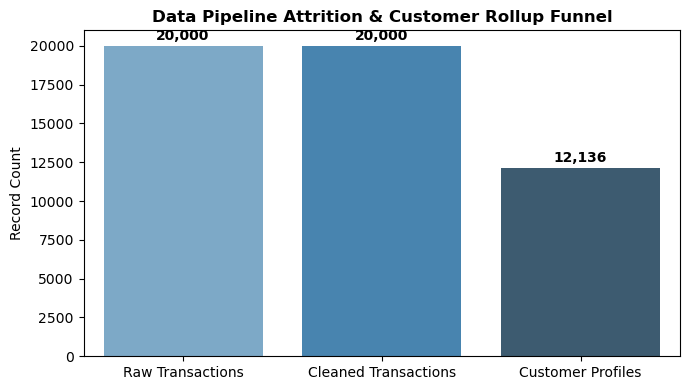


--- Recency & Churn by Product Type ---
              Transactions  Avg_Recency_Days  Churn_Rate_Pct
Product Type                                                
Headphones            2011             96.93           46.84
Laptop                3973            114.38           52.25
Smartphone            5978            119.11           53.20
Smartwatch            3934            112.47           51.53
Tablet                4104            114.64           52.61


In [5]:
# ==============================================================================
# 1B. DATA CLEANING FUNNEL, ADD-ON RATE & CATEGORY CONTEXT
# ==============================================================================
raw_rows = len(df)
valid_tx_df = df.dropna(subset=["Customer ID", "Purchase Date", "Total Price"]).copy()
valid_tx_df = valid_tx_df[valid_tx_df["Total Price"] >= 0]
cleaned_rows = len(valid_tx_df)

# Add-on attachment indicator per transaction
valid_tx_df["Has_Addon"] = (
    valid_tx_df["Add-on Total"].fillna(0) > 0
).astype(int)

# Dominant Product Type per customer
primary_prod = (
    valid_tx_df.groupby("Customer ID")["Product Type"]
    .agg(lambda s: s.mode().iloc[0] if not s.mode().empty else "Unknown")
    .reset_index()
    .rename(columns={"Product Type": "Primary_Product_Type"})
)

addon_stats = (
    valid_tx_df.groupby("Customer ID")["Has_Addon"]
    .mean()
    .reset_index()
    .rename(columns={"Has_Addon": "Addon_Attachment_Rate"})
)

customer_df = customer_df.merge(primary_prod, on="Customer ID", how="left")
customer_df = customer_df.merge(addon_stats, on="Customer ID", how="left")
customer_df["Addon_Attachment_Rate"] = customer_df["Addon_Attachment_Rate"].fillna(0.0)

print("--- Data Attrition & Aggregation Funnel ---")
print(f"Raw Transactions:     {raw_rows:,}")
print(f"Cleaned Transactions: {cleaned_rows:,} (dropped {raw_rows - cleaned_rows:,})")
print(f"Unique Customers:     {len(customer_df):,}")

# Funnel Bar Chart
fig, ax = plt.subplots(figsize=(7, 4))
stages = ["Raw Transactions", "Cleaned Transactions", "Customer Profiles"]
counts = [raw_rows, cleaned_rows, len(customer_df)]
sns.barplot(x=stages, y=counts, palette="Blues_d", ax=ax)
for i, v in enumerate(counts):
    ax.text(i, v + max(counts) * 0.02, f"{v:,}", ha="center", fontweight="bold")
ax.set_title("Data Pipeline Attrition & Customer Rollup Funnel", fontweight="bold")
ax.set_ylabel("Record Count")
plt.tight_layout()
plt.show()

# Category-level Recency & Churn check (Point 2D)
cat_summary = (
    valid_tx_df.merge(customer_df[["Customer ID", "Recency", "Churned"]], on="Customer ID")
    .groupby("Product Type")
    .agg(
        Transactions=("Customer ID", "count"),
        Avg_Recency_Days=("Recency", "mean"),
        Churn_Rate_Pct=("Churned", lambda s: s.mean() * 100),
    )
    .round(2)
)
print("\n--- Recency & Churn by Product Type ---")
print(cat_summary)

In [6]:
# ==============================================================================
# 2. CUSTOMER SEGMENTATION (K-MEANS & PCA)
# ==============================================================================
segmentation_features = [
    "Recency",
    "Frequency",
    "Monetary",
    "Avg_Rating",
    "Age",
    "Loyalty_Member",
    "Cancellation_Rate",
]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(customer_df[segmentation_features])

# Fit optimal K-Means (defaulting to k=4 personas)
OPTIMAL_K = 4
kmeans = KMeans(n_clusters=OPTIMAL_K, random_state=42, n_init=10)
customer_df["Segment"] = kmeans.fit_predict(X_scaled)

# Assign readable persona labels based on cluster feature means
cluster_means = customer_df.groupby("Segment")[segmentation_features].mean()
print("\n--- Cluster Feature Centroids (Raw Values) ---")
print(cluster_means)

# 2D Dimensionality Reduction for visualization
pca = PCA(n_components=2, random_state=42)
pca_coords = pca.fit_transform(X_scaled)
customer_df["PCA1"] = pca_coords[:, 0]
customer_df["PCA2"] = pca_coords[:, 1]

C:\Users\jasqi\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\jasqi\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\jasqi\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\jasqi\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^


--- Cluster Feature Centroids (Raw Values) ---
            Recency  Frequency      Monetary  Avg_Rating        Age  \
Segment                                                               
0        138.962789   1.496151   4449.242352    3.138794  48.764756   
1        153.258604   1.141101   3577.667571    3.104474  49.168633   
2         70.022330   2.800149  10984.026197    2.941897  48.843320   
3        148.984440   1.311207   3477.286287    3.169621  49.418160   

         Loyalty_Member  Cancellation_Rate  
Segment                                     
0              1.000000           0.335721  
1              0.000000           0.998853  
2              0.093413           0.323493  
3              0.000000           0.063555  


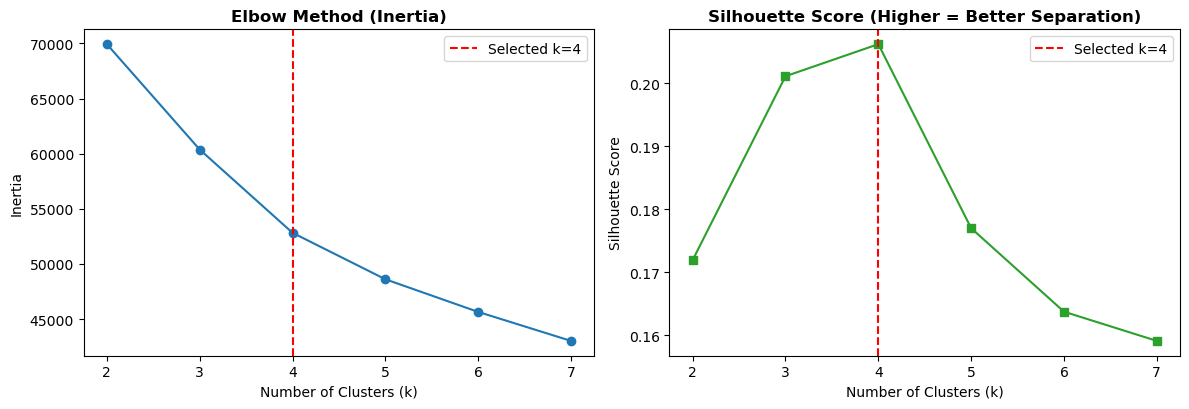


--- Expanded Segment Persona Table ---
        Recency       Frequency        Monetary       Avg_Rating          Age  \
           mean count      mean count      mean count       mean count   mean   
Segment                                                                         
0        138.96  2338      1.50  2338   4449.24  2338       3.14  2338  48.76   
1        153.26  2034      1.14  2034   3577.67  2034       3.10  2034  49.17   
2         70.02  2687      2.80  2687  10984.03  2687       2.94  2687  48.84   
3        148.98  5077      1.31  5077   3477.29  5077       3.17  5077  49.42   

              Loyalty_Member       Cancellation_Rate        \
        count           mean count              mean count   
Segment                                                      
0        2338           1.00  2338              0.34  2338   
1        2034           0.00  2034              1.00  2034   
2        2687           0.09  2687              0.32  2687   
3        5077       

In [7]:
from sklearn.metrics import silhouette_score

# ==============================================================================
# 2B. CLUSTER VALIDATION (ELBOW & SILHOUETTE) & PERSONA SUMMARY
# ==============================================================================
inertias = []
sil_scores = []
k_values = range(2, 8)

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels, sample_size=3000, random_state=42))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(list(k_values), inertias, marker="o", color="#1f77b4")
axes[0].axvline(OPTIMAL_K, color="red", linestyle="--", label=f"Selected k={OPTIMAL_K}")
axes[0].set_title("Elbow Method (Inertia)", fontweight="bold")
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("Inertia")
axes[0].legend()

axes[1].plot(list(k_values), sil_scores, marker="s", color="#2ca02c")
axes[1].axvline(OPTIMAL_K, color="red", linestyle="--", label=f"Selected k={OPTIMAL_K}")
axes[1].set_title("Silhouette Score (Higher = Better Separation)", fontweight="bold")
axes[1].set_xlabel("Number of Clusters (k)")
axes[1].set_ylabel("Silhouette Score")
axes[1].legend()
plt.tight_layout()
plt.show()

profile_cols = segmentation_features + ["Addon_Attachment_Rate", "Churned"]
persona_table = customer_df.groupby("Segment")[profile_cols].agg(["mean", "count"])
print("\n--- Expanded Segment Persona Table ---")
print(persona_table.round(2))

In [8]:
# ==============================================================================
# 3. PREDICTIVE CHURN MODELING (RANDOM FOREST)
# ==============================================================================
churn_features = [
    "Frequency",
    "Monetary",
    "Avg_Rating",
    "Age",
    "Loyalty_Member",
    "Cancellation_Rate",
    "Segment",
]

X_churn = pd.get_dummies(
    customer_df[churn_features], columns=["Segment"], drop_first=True
)
y_churn = customer_df["Churned"]

X_train, X_test, y_train, y_test = train_test_split(
    X_churn, y_churn, test_size=0.25, random_state=42, stratify=y_churn
)

rf_classifier = RandomForestClassifier(
    n_estimators=100, max_depth=6, random_state=42
)
rf_classifier.fit(X_train, y_train)

y_pred = rf_classifier.predict(X_test)
y_prob = rf_classifier.predict_proba(X_test)[:, 1]

print("\n--- Churn Prediction Performance ---")
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}")
print(classification_report(y_test, y_pred))

# Attach calibrated Churn Probability scores to the master customer table
customer_df["Churn_Risk_Score"] = rf_classifier.predict_proba(X_churn)[:, 1]


--- Churn Prediction Performance ---
ROC-AUC Score: 0.6949
              precision    recall  f1-score   support

           0       0.69      0.41      0.52      1238
           1       0.68      0.87      0.77      1796

    accuracy                           0.69      3034
   macro avg       0.69      0.64      0.64      3034
weighted avg       0.69      0.69      0.66      3034



--- Model Comparison (Leakage-Free Features) ---
Random Forest  | ROC-AUC: 0.6949 | Brier Score: 0.2104
Logistic Regr. | ROC-AUC: 0.6638 | Brier Score: 0.2131


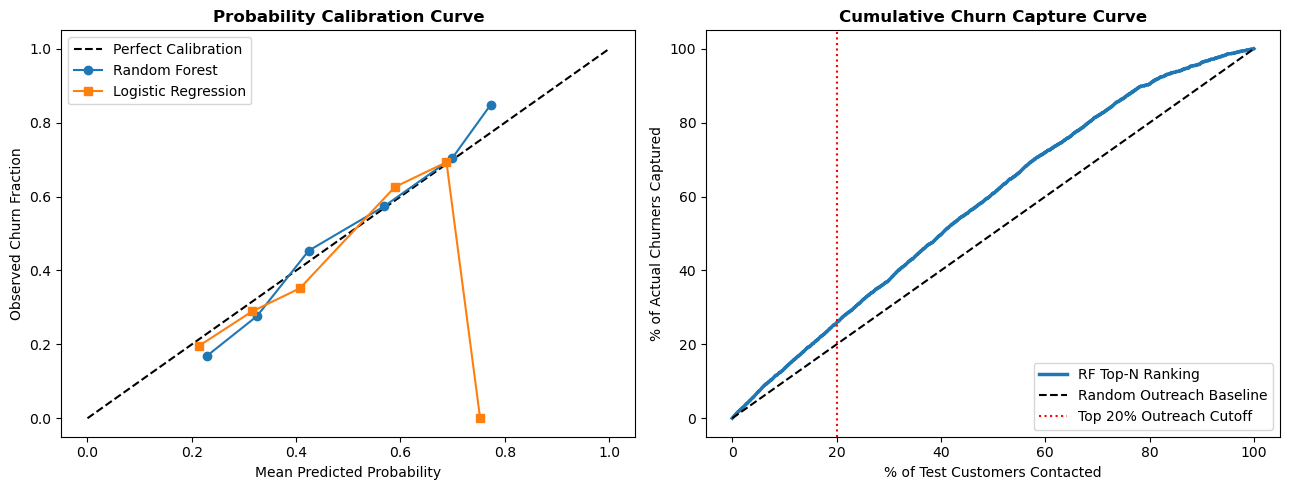

Saved customer_analytics_processed.csv successfully.


In [9]:
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss
from sklearn.pipeline import make_pipeline

# ==============================================================================
# 3B. LOGISTIC BASELINE, BRIER CALIBRATION, LIFT CURVE & CSV EXPORT
# ==============================================================================
log_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))
log_model.fit(X_train, y_train)

rf_probs = y_prob
log_probs = log_model.predict_proba(X_test)[:, 1]

print("--- Model Comparison (Leakage-Free Features) ---")
print(f"Random Forest  | ROC-AUC: {roc_auc_score(y_test, rf_probs):.4f} | Brier Score: {brier_score_loss(y_test, rf_probs):.4f}")
print(f"Logistic Regr. | ROC-AUC: {roc_auc_score(y_test, log_probs):.4f} | Brier Score: {brier_score_loss(y_test, log_probs):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Calibration Curve
prob_true_rf, prob_pred_rf = calibration_curve(y_test, rf_probs, n_bins=8)
prob_true_lg, prob_pred_lg = calibration_curve(y_test, log_probs, n_bins=8)
axes[0].plot([0, 1], [0, 1], "k--", label="Perfect Calibration")
axes[0].plot(prob_pred_rf, prob_true_rf, marker="o", label="Random Forest")
axes[0].plot(prob_pred_lg, prob_true_lg, marker="s", label="Logistic Regression")
axes[0].set_title("Probability Calibration Curve", fontweight="bold")
axes[0].set_xlabel("Mean Predicted Probability")
axes[0].set_ylabel("Observed Churn Fraction")
axes[0].legend()

# Cumulative Gains / Capture Curve
order = np.argsort(-rf_probs)
y_sorted = y_test.values[order]
pct_targeted = np.linspace(0, 1, len(y_sorted) + 1)
cum_captured = np.concatenate([[0], np.cumsum(y_sorted) / y_sorted.sum()])

axes[1].plot(pct_targeted * 100, cum_captured * 100, color="#1f77b4", lw=2.5, label="RF Top-N Ranking")
axes[1].plot([0, 100], [0, 100], "k--", label="Random Outreach Baseline")
axes[1].axvline(20, color="red", linestyle=":", label="Top 20% Outreach Cutoff")
axes[1].set_title("Cumulative Churn Capture Curve", fontweight="bold")
axes[1].set_xlabel("% of Test Customers Contacted")
axes[1].set_ylabel("% of Actual Churners Captured")
axes[1].legend()

plt.tight_layout()
plt.show()

# Export processed customer table for Streamlit app
customer_df.to_csv("customer_analytics_processed.csv", index=False)
print("Saved customer_analytics_processed.csv successfully.")

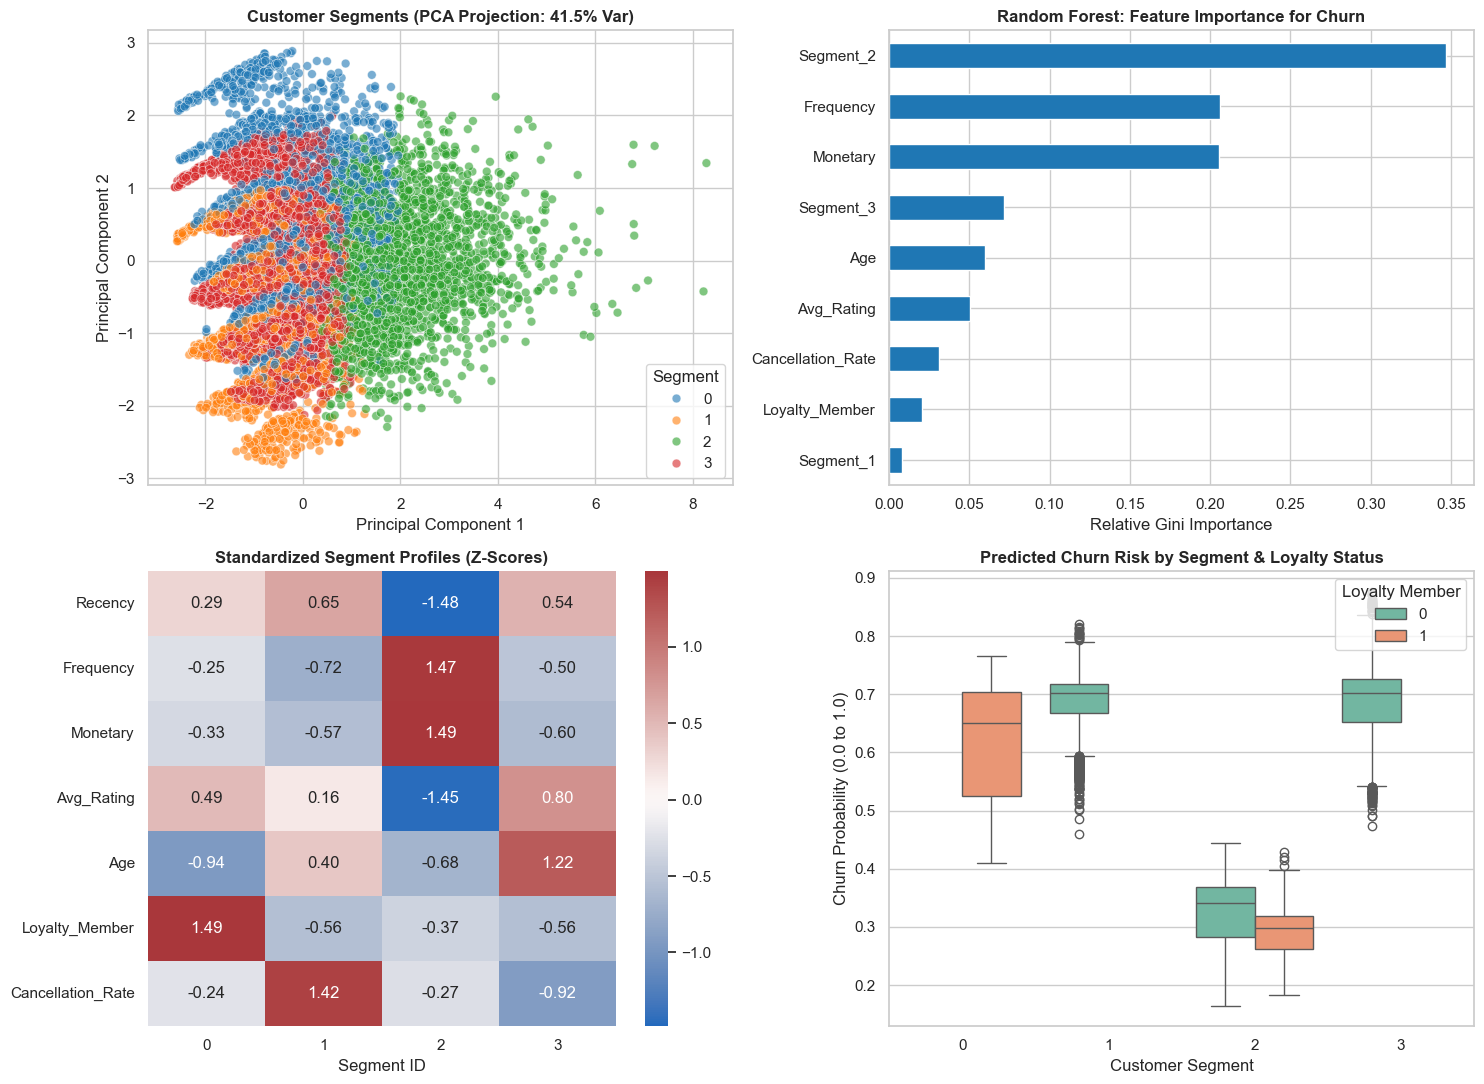

In [10]:
# ==============================================================================
# 4. DIAGNOSTIC VISUALIZATIONS
# ==============================================================================
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# Plot 1: 2D PCA Customer Clusters
sns.scatterplot(
    data=customer_df,
    x="PCA1",
    y="PCA2",
    hue="Segment",
    palette="tab10",
    alpha=0.6,
    s=40,
    ax=axes[0, 0],
)
axes[0, 0].set_title(
    f"Customer Segments (PCA Projection: {pca.explained_variance_ratio_.sum():.1%} Var)",
    fontsize=12,
    weight="bold",
)
axes[0, 0].set_xlabel("Principal Component 1")
axes[0, 0].set_ylabel("Principal Component 2")

# Plot 2: Relative Feature Importance for Churn Risk
importances = pd.Series(rf_classifier.feature_importances_, index=X_churn.columns).sort_values(
    ascending=True
)
importances.plot(kind="barh", ax=axes[0, 1], color="#1f77b4")
axes[0, 1].set_title("Random Forest: Feature Importance for Churn", fontsize=12, weight="bold")
axes[0, 1].set_xlabel("Relative Gini Importance")

# Plot 3: Segment Profile Heatmap (Z-score standardized)
norm_cluster_profile = (cluster_means - cluster_means.mean()) / cluster_means.std()
sns.heatmap(
    norm_cluster_profile.T,
    cmap="vlag",
    annot=True,
    fmt=".2f",
    center=0,
    cbar=True,
    ax=axes[1, 0],
)
axes[1, 0].set_title("Standardized Segment Profiles (Z-Scores)", fontsize=12, weight="bold")
axes[1, 0].set_xlabel("Segment ID")

# Plot 4: Churn Risk Score Distribution by Segment & Loyalty
sns.boxplot(
    data=customer_df,
    x="Segment",
    y="Churn_Risk_Score",
    hue="Loyalty_Member",
    palette="Set2",
    ax=axes[1, 1],
)
axes[1, 1].set_title(
    "Predicted Churn Risk by Segment & Loyalty Status", fontsize=12, weight="bold"
)
axes[1, 1].set_xlabel("Customer Segment")
axes[1, 1].set_ylabel("Churn Probability (0.0 to 1.0)")
axes[1, 1].legend(title="Loyalty Member", loc="upper right")

plt.tight_layout()
plt.show()

In [11]:
# ==============================================================================
# 5. EXPORT PREPARED DATA FOR APP PROTOTYPE
# ==============================================================================
# customer_df.to_csv("customer_analytics_processed.csv", index=False)